# Эксперимент 1. Одно событие на заключение

Вариант «категории × 2», поиск способов поднять precision моделей.

**Идея.** В основном варианте заключение с несколькими категориями даёт цепочку событий (по тяжести, время 0).
Майнеры видят в этих цепочках параллельность и циклы и строят модель, которая разрешает много лишних путей.
Здесь от каждого заключения остаётся **одна категория — самая тяжёлая** (при равной тяжести — случайная, seed 42;
`Justice` — только если в заключении нет других категорий). Трасса человека становится простой
последовательностью заключений.

**Зачем.** Проверить, насколько низкая precision вызвана развилками внутри заключения. В Этапе 1 вариант
«одна категория на эпизод» давал precision около 0.87 против 0.65–0.75 с развилками.

**Цена.** Теряются менее тяжёлые категории заключения (в основном варианте 8 484 шага из 21 866 с развилкой).

**Как запустить.** Окружение `D:\Git\diploma\.venv`, открыть ноутбук из этой папки, *Run All*. Вход — таблица этапа 0
(`jupyter lab\stage0 - data\out\compas_custody_charges.csv`), общий код журнала — `x2_common.py` рядом (тот же, что в
`oldcase_x2`). Результаты пишутся в `out\` этой папки.

**Как сравниваются модели.** Как в `oldcase_x2`: люди делятся на train 80% / test 20% (seed 42), модели строятся на
train, fitness и precision считаются token-based replay на первых 2 000 людях train и test. Базовая линия — вариант
`oldcase_x2` (29 состояний, порядок по тяжести): HM 0.9 — fitness 0.982, precision 0.543; IM 0.2 — 0.994 / 0.383.

## Шаг 0. Настройки

In [1]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
for gv in [Path(r"D:\Graphviz\bin")]:
    if gv.exists() and str(gv) not in os.environ["PATH"]:
        os.environ["PATH"] = str(gv) + os.pathsep + os.environ["PATH"]
import pm4py
import x2_common as X

HERE = Path.cwd()
ROOT = HERE.parent.parent                       # jupyter lab (на компьютере) или корень репозитория
CANDIDATES = [ROOT / "stage0 - data" / "out" / "compas_custody_charges.csv",
              ROOT / "stage0-data" / "compas_custody_charges.csv"]
DATA = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUT = HERE / "out"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

EXP = "x2_exp1_one_event"
BUILD = {'one_event': True}       # параметры журнала
MERGE_RARE = False      # слить редкие OldCase: X
MIN_EVENTS = 300            # порог «редкого» состояния
MODELS = ['HM_0.5', 'HM_0.9', 'HM_0.95', 'IM_0.2', 'IM_0.5']
EVAL_CASES = 2000           # людей в выборках train/test для fitness/precision
RUN_ILP = False             # ILP Miner (долго)
ALIGN_CASES = 2000          # precision через выравнивания для HM 0.9 на стольких людях из test (0 — не считать);
                            # чем меньше выборка, тем ниже precision (часть префиксов не встречается), поэтому 2000
print("pm4py", pm4py.__version__, "| вход:", DATA, DATA.exists())


def show(path, max_px=1400):
    from io import BytesIO
    from PIL import Image as PILImage
    PILImage.MAX_IMAGE_PIXELS = None
    im = PILImage.open(path)
    im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=80)
    display(Image(data=buf.getvalue(), format="jpeg"))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9 | вход: /tmp/claude-0/w/jl/stage0 - data/out/compas_custody_charges.csv True


## Шаг 1. Журнал событий

In [2]:
ch, ep = X.load(DATA)
merge_old = ()
if MERGE_RARE:
    base_ev, _, _ = X.build("x2", ch, ep, **{k: v for k, v in BUILD.items() if k != "merge_old"})
    vc = base_ev["concept:name"].value_counts()
    merge_old = sorted(a for a, n in vc.items() if a.startswith(X.OLD_PREFIX) and n < MIN_EVENTS)
    print("сливаются в «OldCase: Other»:", ", ".join(f"{a} ({vc[a]})" for a in merge_old))
ev, st, info = X.build("x2", ch, ep, merge_old=merge_old, **BUILD)
info

{'variant': 'x2',
 'people': 10580,
 'episodes': 21716,
 'justice_steps': 0,
 'steps': 21716,
 'events': 21716,
 'transitions': 11136,
 'people_repeat': 5209,
 'multi_type_steps': 0,
 'activities': 28,
 'obs_end': '2016-04-19'}

In [3]:
log = pm4py.format_dataframe(ev[["case:concept:name", "concept:name", "time:timestamp"]].copy(),
                             case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
dfg, sa, ea = pm4py.discover_dfg(log)
traces = st.groupby("id")["state"].agg(" → ".join).value_counts()
stats = pd.Series({"состояний": log["concept:name"].nunique(), "событий": len(log), "шагов": len(st),
                   "дуг DFG": len(dfg), "петель DFG (X→X)": sum(a == b for a, b in dfg),
                   "вариантов трасс": len(traces), "людей с уникальной трассой": int((traces == 1).sum())})
ev.to_csv(OUT / f"event_log_{EXP}.csv", index=False)
stats.to_csv(OUT / "log_stats.csv", header=["value"])
print(log["concept:name"].value_counts().to_string())
stats

concept:name
Violent                  4599
Property                 3690
Drug                     3359
Traffic                  2238
OldCase: Property        1601
OldCase: Drug            1534
OldCase: Violent          862
Unknown                   653
Fraud                     530
OldCase: Traffic          506
ResistPolice              503
PublicOrder               285
Tampering                 246
Weapon                    238
Sex                       229
OldCase: Fraud            197
OldCase: ResistPolice     122
OldCase: Weapon           105
OldCase: Sex               67
OldCase: Tampering         64
OldCase: PublicOrder       26
Justice                    22
Conspiracy                 19
OldCase: Conspiracy         8
Minors                      7
OldCase: Justice            4
OldCase: Minors             1
Other                       1


состояний                        28
событий                       21716
шагов                         21716
дуг DFG                         368
петель DFG (X→X)                 24
вариантов трасс                1729
людей с уникальной трассой     1321
dtype: int64

## Шаг 2. Граф: DFG (30% путей) и сеть Петри Heuristics Miner 0.9

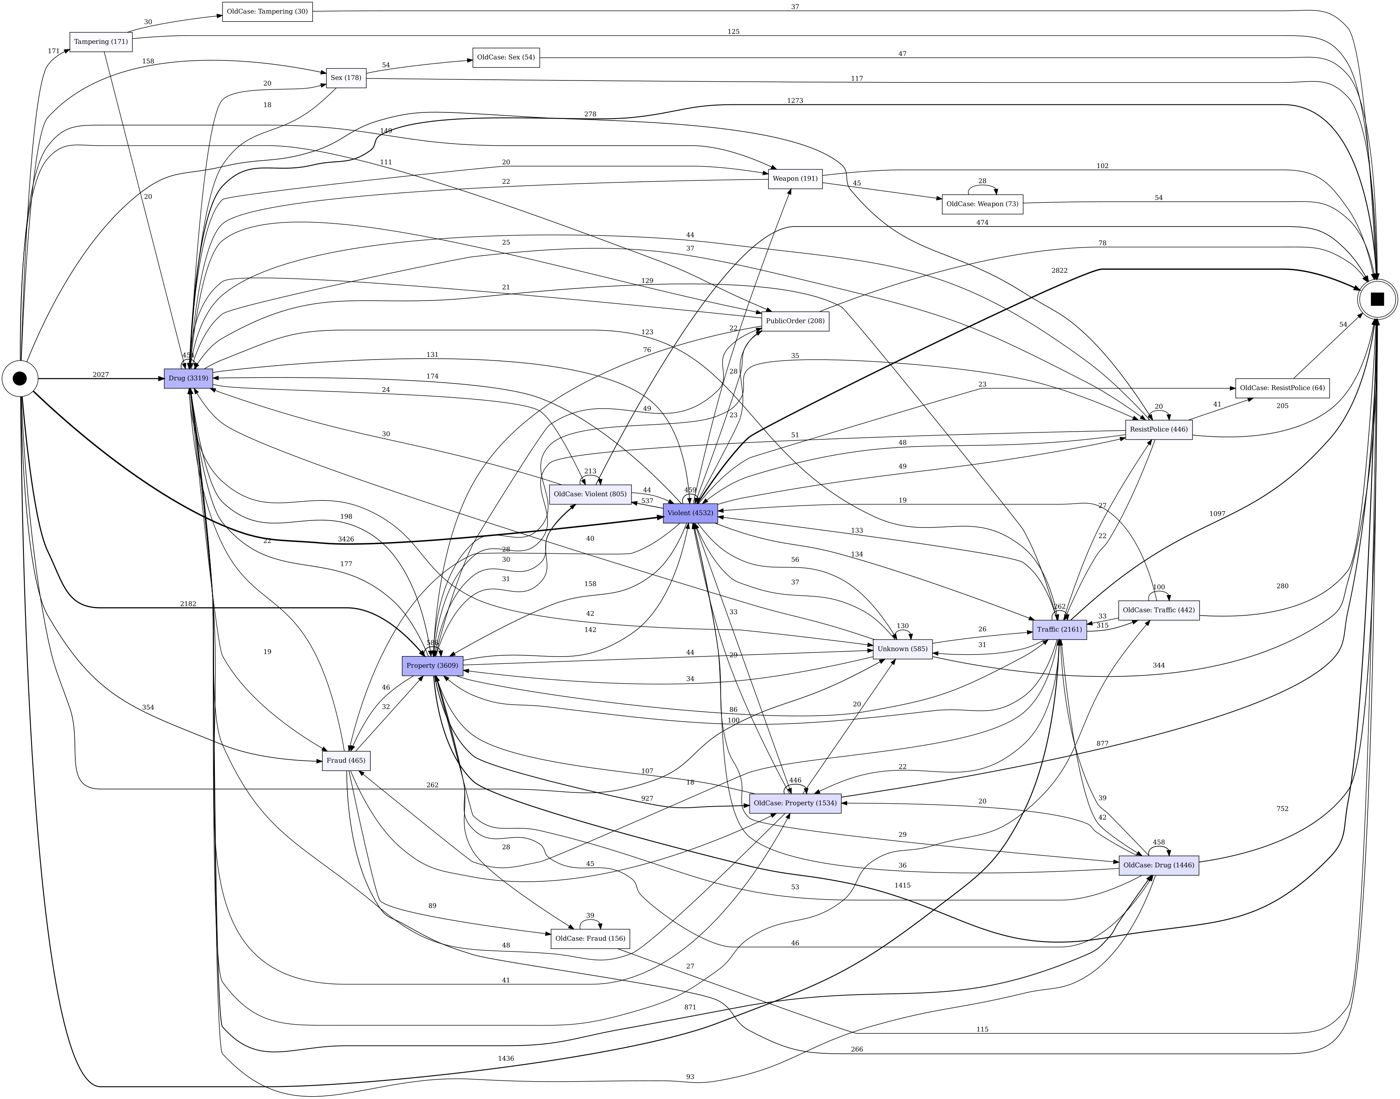

In [4]:
dfg_f, sa_f, ea_f = pm4py.filter_dfg_paths_percentage(dfg, sa, ea, 0.3)
# у pm4py 2.7.23.9 рисунок падает, если начальная/конечная активность не осталась ни на одной дуге — убираем такие
acts_f = {a for k in dfg_f for a in k}
sa_f = {a: n for a, n in sa_f.items() if a in acts_f}
ea_f = {a: n for a, n in ea_f.items() if a in acts_f}
pm4py.save_vis_dfg(dfg_f, sa_f, ea_f, str(FIG / "dfg_frequency_paths30.png"))
show(FIG / "dfg_frequency_paths30.png")

HM 0.9 на всём журнале: мест 50, переходов 211


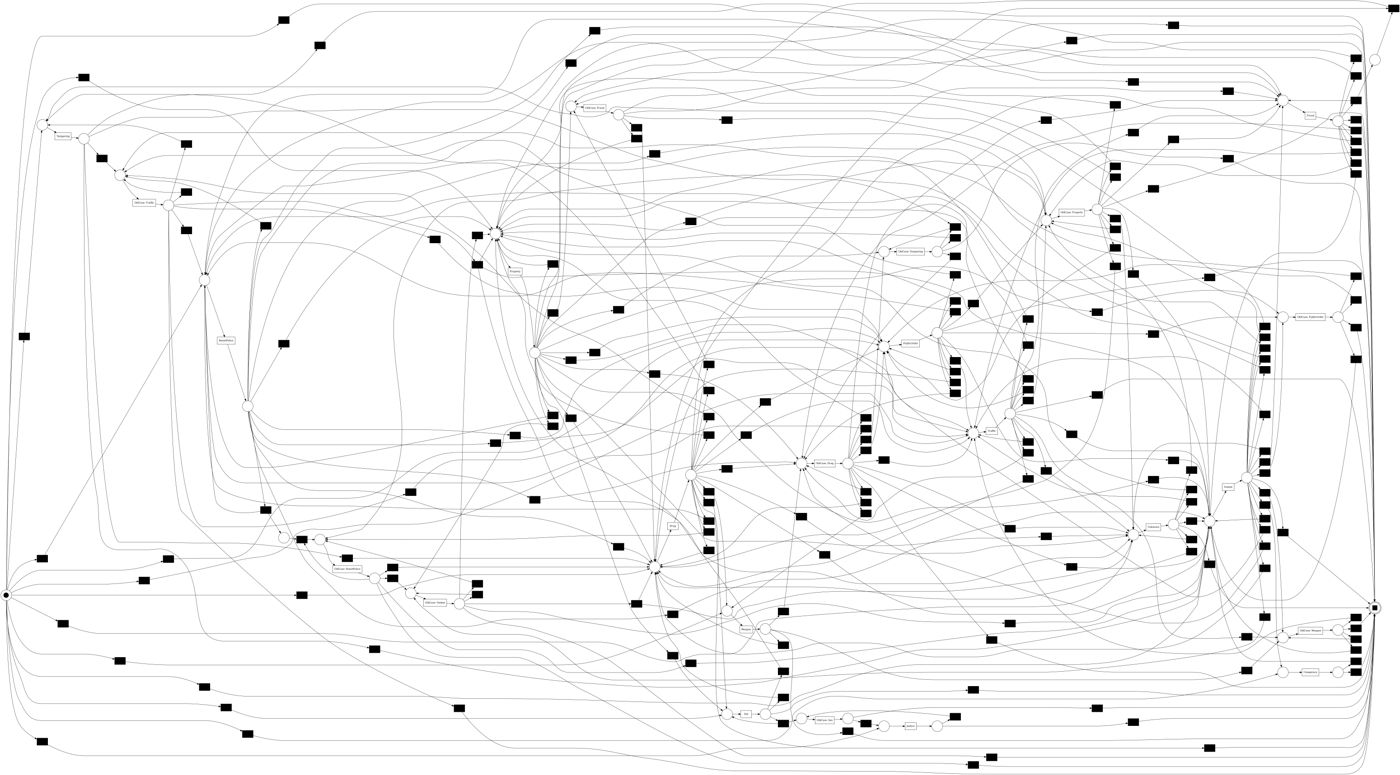

In [5]:
net, im, fm = pm4py.discover_petri_net_heuristics(log, dependency_threshold=0.9)
pm4py.save_vis_petri_net(net, im, fm, str(FIG / "petri_HM_dep0.9.png"))
print(f"HM 0.9 на всём журнале: мест {len(net.places)}, переходов {len(net.transitions)}")
show(FIG / "petri_HM_dep0.9.png")

## Шаг 3. Модели и качество

Названия моделей: `HM_d` — Heuristics Miner с порогом зависимости d; `HM_0.9_min30` — то же, дуги реже 30 раз
отбрасываются; `HM_0.9_and0.95` — то же, параллельность (AND) объявляется только при мере ≥ 0.95; `IM_n` — Inductive Miner с порогом шума n; `*_freq` — модель построена только по людям с
трассой, которая встречается хотя бы у двух человек (проверка — на всех); `ILP` — ILP Miner.

In [6]:
train, test = X.split_people(log)
train_s, test_s = X.sample_cases(train, EVAL_CASES), X.sample_cases(test, EVAL_CASES)


def frequent_train():
    # люди из train, чья трасса (последовательность событий) встречается хотя бы у двух человек
    seq = train.groupby("case:concept:name")["concept:name"].agg(tuple)
    n = seq.map(seq.value_counts())
    return train[train["case:concept:name"].isin(n[n >= 2].index)]


def discover(name):
    if name.startswith("HM_"):
        parts = name.split("_")
        lg = frequent_train() if name.endswith("_freq") else train
        kw = dict(dependency_threshold=float(parts[1]))
        if "min30" in name:
            kw["min_dfg_occurrences"] = 30
        return pm4py.discover_petri_net_heuristics(lg, **kw)
    if name.startswith("IM_"):
        lg = frequent_train() if name.endswith("_freq") else train
        return pm4py.discover_petri_net_inductive(lg, noise_threshold=float(name.split("_")[1]))
    if name == "ILP":
        return pm4py.discover_petri_net_ilp(train)
    raise ValueError(name)


models, times = {}, {}
for name in MODELS:
    if name == "ILP" and not RUN_ILP:
        continue
    t0 = time.time()
    models[name] = discover(name)
    times[name] = round(time.time() - t0)
    print(f"{name}: построена за {times[name]} с")

HM_0.5: построена за 0 с
HM_0.9: построена за 0 с


HM_0.95: построена за 0 с


IM_0.2: построена за 0 с
IM_0.5: построена за 0 с


In [7]:
quality = X.evaluate(models, train_s, test_s)
quality["discover_sec"] = quality["model"].map(times)
if ALIGN_CASES and "HM_0.9" in models:
    t0 = time.time()
    pa = pm4py.precision_alignments(X.sample_cases(test, ALIGN_CASES), *models["HM_0.9"])
    quality.loc[(quality["model"] == "HM_0.9") & (quality["split"] == "test"), "precision_align"] = round(pa, 4)
    print(f"HM 0.9: precision через выравнивания на {ALIGN_CASES} людях = {pa:.4f} ({time.time() - t0:.0f} с)")
quality.to_csv(OUT / "model_quality.csv", index=False)
quality[quality["split"] == "test"]

{'model': 'HM_0.5', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9209, 'pct_fit_traces': 66.15, 'precision_tbr': 0.7608, 'f1': 0.8332, 'places': 79, 'transitions': 251, 'silent': 224, 'sec': 2}


{'model': 'HM_0.5', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9187, 'pct_fit_traces': 63.95, 'precision_tbr': 0.8209, 'f1': 0.867, 'places': 79, 'transitions': 251, 'silent': 224, 'sec': 2}


{'model': 'HM_0.9', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9822, 'pct_fit_traces': 89.8, 'precision_tbr': 0.7333, 'f1': 0.8397, 'places': 48, 'transitions': 198, 'silent': 175, 'sec': 2}


{'model': 'HM_0.9', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9831, 'pct_fit_traces': 90.15, 'precision_tbr': 0.796, 'f1': 0.8797, 'places': 48, 'transitions': 198, 'silent': 175, 'sec': 2}


{'model': 'HM_0.95', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9833, 'pct_fit_traces': 91.0, 'precision_tbr': 0.7354, 'f1': 0.8415, 'places': 48, 'transitions': 196, 'silent': 173, 'sec': 2}


...

{'model': 'IM_0.2', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9757, 'pct_fit_traces': 79.6, 'precision_tbr': 0.5286, 'f1': 0.6857, 'places': 81, 'transitions': 126, 'silent': 99, 'sec': 3}


{'model': 'IM_0.5', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9335, 'pct_fit_traces': 67.6, 'precision_tbr': 0.4782, 'f1': 0.6324, 'places': 60, 'transitions': 105, 'silent': 78, 'sec': 1}


{'model': 'IM_0.5', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9333, 'pct_fit_traces': 66.95, 'precision_tbr': 0.5512, 'f1': 0.6931, 'places': 60, 'transitions': 105, 'silent': 78, 'sec': 1}


HM 0.9: precision через выравнивания на 2000 людях = 0.7963 (5 с)


,model,split,cases,fitness_tbr,pct_fit_traces,precision_tbr,f1,places,transitions,silent,sec,discover_sec,precision_align
1,HM_0.5,test,2000,0.9187,63.95,0.8209,0.8670,79,251,224,2,0,NaN
3,HM_0.9,test,2000,0.9831,90.15,0.7960,0.8797,48,198,175,2,0,0.7963
5,HM_0.95,test,2000,0.9841,91.40,0.7960,0.8801,48,196,173,2,0,NaN
7,IM_0.2,test,2000,0.9757,79.60,0.5286,0.6857,81,126,99,3,0,NaN
9,IM_0.5,test,2000,0.9333,66.95,0.5512,0.6931,60,105,78,1,0,NaN


## Шаг 4. Сравнение с основным вариантом oldcase_x2

In [8]:
BASE = pd.DataFrame({"model": ["HM_0.5", "HM_0.9", "IM_0.0", "IM_0.2", "IM_0.5"],
                     "fitness_base": [0.9415, 0.9821, 1.0, 0.9938, 0.9716],
                     "precision_base": [0.6136, 0.5430, 0.3688, 0.3828, 0.4563]})
cmp = quality[quality["split"] == "test"][["model", "fitness_tbr", "precision_tbr", "f1"]].merge(BASE, on="model", how="left")
cmp["Δ precision"] = (cmp["precision_tbr"] - cmp["precision_base"]).round(4)
cmp.to_csv(OUT / "compare_with_oldcase_x2.csv", index=False)
cmp

,model,fitness_tbr,precision_tbr,f1,fitness_base,precision_base,Δ precision
0,HM_0.5,0.9187,0.8209,0.8670,0.9415,0.6136,0.2073
1,HM_0.9,0.9831,0.7960,0.8797,0.9821,0.5430,0.2530
2,HM_0.95,0.9841,0.7960,0.8801,NaN,NaN,NaN
3,IM_0.2,0.9757,0.5286,0.6857,0.9938,0.3828,0.1458
4,IM_0.5,0.9333,0.5512,0.6931,0.9716,0.4563,0.0949


# Этапы 2–3 (п. 1.1 плана): параметры переходов и модели выживаемости

Кейс: эксп. 1 «категории × 2, одно событие на заключение». Журнал и граф этапа 1 построены выше; здесь к ним добавляются

- **Этап 2.** Параметры переходов: вероятности $p_{ij}$ и распределения времени между заключениями.
- **Этап 3.** Признаки объекта (возраст, пол, раса, исходный балл COMPAS) и признаки события (тяжесть,
  число обвинений, длительность заключения, номер заключения, старое дело) и модели выживаемости между
  состояниями: CoxPH, дерево и случайный лес выживаемости; влияние признаков на переходы.

**Одна строка = одно заключение человека** (таблица `E`). Из каждого заключения $A$ человек выходит на свободу
и либо попадает в следующее заключение $B$ (переход $A \to B$), либо наблюдение кончается (цензура).

- **Время перехода** $T$ — время на свободе: от выхода из $A$ до входа в $B$, дни (пересечения заключений
  в данных → 0). Это время риска для конкурирующих рисков.
- **Тип следующего события** $K$ — состояние $B$. Пара $(T, K)$ — то, что моделируется в п. 1.2 плана.
- **Цензура.** Последнее заключение человека цензурировано: $T$ — от выхода до конца наблюдения
  (`obs_end`), терминального состояния END нет. Кто на конец наблюдения ещё в заключении, времени на свободе
  не имеет и в моделях выживаемости не участвует (`at_risk = False`), но учтён в долях цензуры.

Состояние заключения — его единственное событие из журнала этапа 1 (самая тяжёлая категория, `X` или `OldCase: X`), поэтому граф этапа 1 и переходы здесь совпадают.

Общий код этапов 2–3 — `stage23.py` (тот же файл во всех кейсах). Результаты — в `out\stage23\`:
CSV-таблицы, `stage23_tables.xlsx` (все таблицы листами) и рисунки в `figures\`.

In [9]:
import stage23 as ST

DB = next((p for p in [ROOT / "stage0 - data" / "compas.db", ROOT / "stage0-data" / "compas.db"] if p.exists()),
          ROOT / "stage0 - data" / "compas.db")
OUT23 = OUT / "stage23"
FIG23 = OUT23 / "figures"
FIG23.mkdir(parents=True, exist_ok=True)
RUN_RSF = True              # случайный лес выживаемости (около минуты)
MIN_ARC_EVENTS = 50         # модели Кокса по дугам — только для дуг с таким числом переходов

people = ST.compas_people(DB)                       # возраст, пол, раса, балл COMPAS из compas.db
E = ST.episodes_x2(st, ch, people, info["obs_end"])
E.drop(columns=["person_id"]).to_csv(OUT23 / "episodes.csv", index=False)
ST.episodes_summary(E)

людей                               10580.000
заключений                          21716.000
состояний                              28.000
переходов (наблюдались)             11136.000
цензурировано (последние)           10580.000
  из них ещё в заключении             635.000
доля петель X→X                         0.295
медиана дней на свободе до след.      124.000
переходов за 0 дней                   107.000
нет балла COMPAS                       15.000
dtype: float64

**Как читать.** `переходов (наблюдались)` — пары соседних заключений; `цензурировано` — по одному последнему
заключению на человека; `переходов за 0 дней` — следующее заключение началось в день выхода или раньше
(пересечения в данных). `нет балла COMPAS` — у этих людей нет `decile_score`, в моделях этапа 3 они выпадают.

## Этап 2. Параметры переходов

### 2.1. Вероятности переходов

Вложенная цепь Маркова: $p_{ij} = n_{ij} / \sum_k n_{ik}$ — доля переходов в $j$ среди всех **наблюдавшихся**
переходов из $i$. Доля цензуры — доля заключений $i$, после которых следующего заключения не было до конца
наблюдения. $p_{ij}$ не учитывает, когда случился переход и сколько людей не дожило до него под наблюдением;
это делают кумулятивные функции инцидентности в 2.5.

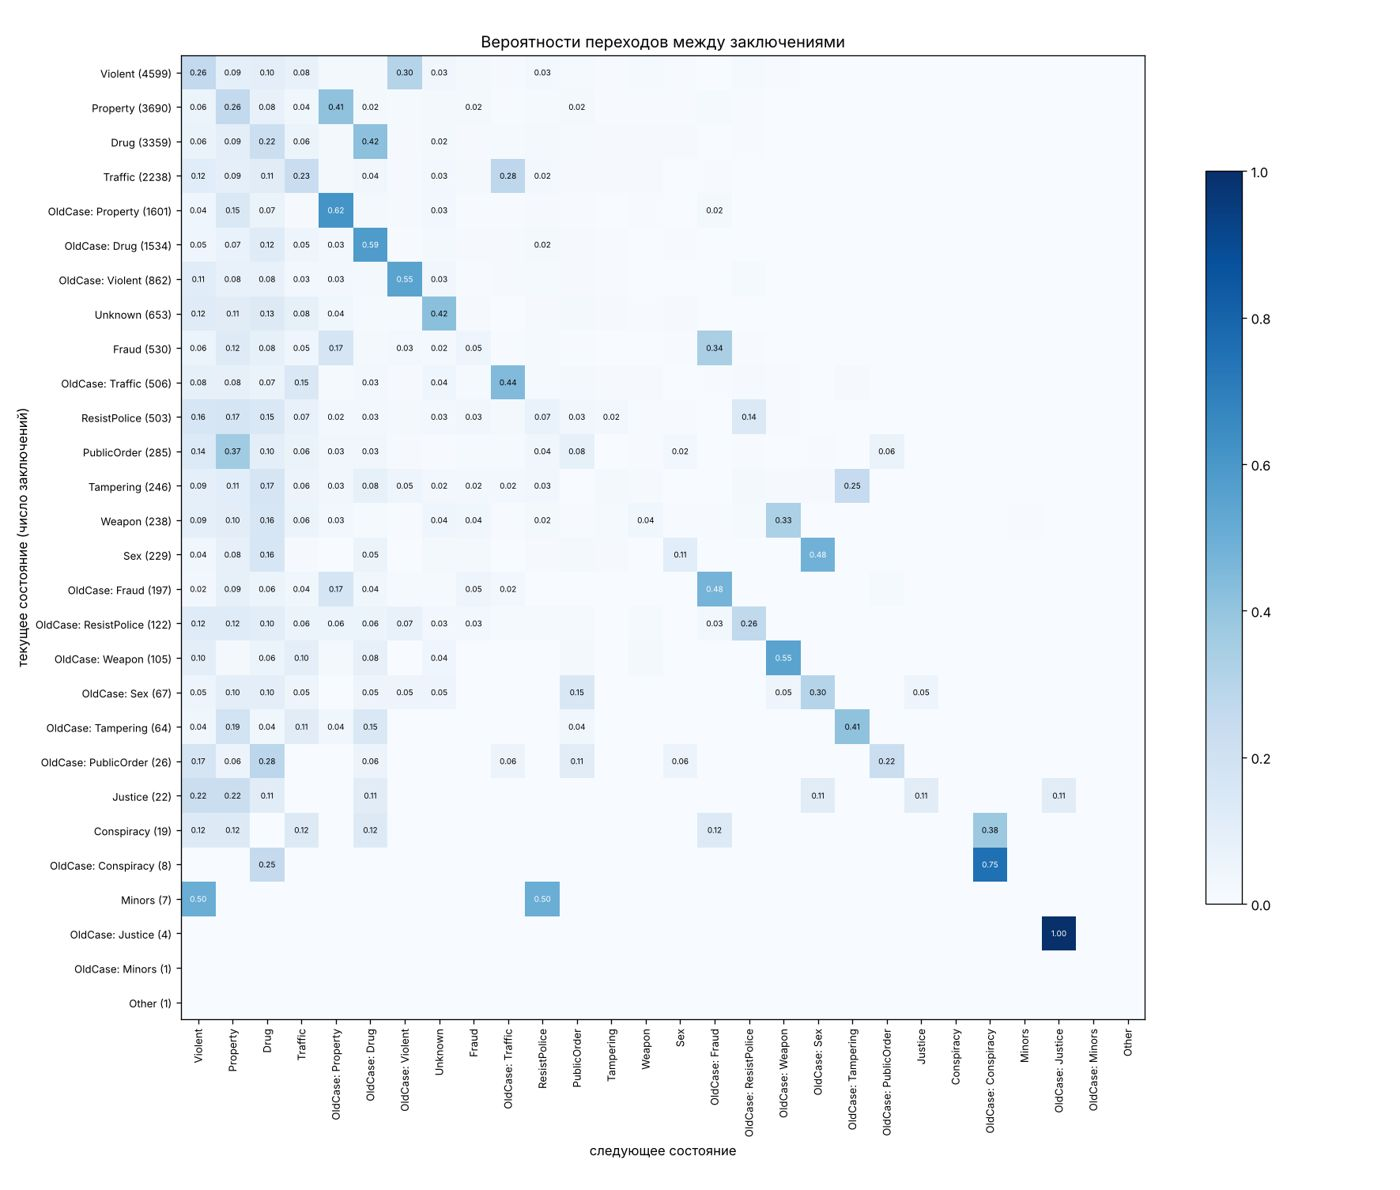

,заключений,переходов,доля цензуры,петля p(i→i)
Violent,4599,1777,0.614,0.258
Property,3690,2275,0.383,0.258
Drug,3359,2086,0.379,0.218
Traffic,2238,1141,0.490,0.230
OldCase: Property,1601,724,0.548,0.616
OldCase: Drug,1534,782,0.490,0.586
OldCase: Violent,862,388,0.550,0.549
Unknown,653,309,0.527,0.421
Fraud,530,264,0.502,0.049
OldCase: Traffic,506,226,0.553,0.442


In [10]:
cnt, P, trans_summary = ST.transition_matrix(E)
cnt.to_csv(OUT23 / "transition_counts.csv")
P.round(4).to_csv(OUT23 / "transition_probs.csv")
trans_summary.to_csv(OUT23 / "transition_summary.csv")
ST.plot_matrix(P, FIG23 / "transition_matrix.png", "Вероятности переходов между заключениями",
               n=trans_summary["заключений"], annotate_min=0.02)
show(FIG23 / "transition_matrix.png")
trans_summary

**Как читать матрицу.** Строка — состояние текущего заключения (в скобках — число заключений), столбец —
следующего; в клетке $p_{ij}$ (подписаны $\ge 0.02$). Диагональ — повтор того же состояния (петля графа).
В таблице: сколько заключений в состоянии, сколько из них закончились переходом, доля цензуры и петля $p_{ii}$.

### 2.2. Время на свободе по дугам

Для каждой дуги $i \to j$ — описательная статистика времени на свободе среди тех, кто совершил этот переход
(дни): число переходов, $p_{ij}$, среднее, квартили, 90-й перцентиль. Показаны дуги с не менее 30 переходами.

In [11]:
arcs23 = ST.arc_times(E)
arcs23.to_csv(OUT23 / "arc_times.csv", index=False)
arcs23[arcs23["n"] >= 30].sort_values("n", ascending=False).head(25)

,from,to,n,p,mean,q25,median,q75,q90
206,Property,OldCase: Property,927,0.407,211.9,63.0,146.0,314.5,492.2
11,Drug,OldCase: Drug,871,0.418,197.4,66.0,136.0,270.5,451.0
213,Property,Property,588,0.258,141.8,26.0,80.0,200.8,368.2
338,Violent,OldCase: Violent,537,0.302,209.4,57.0,140.0,306.0,505.2
347,Violent,Violent,459,0.258,206.7,52.0,134.0,298.0,509.0
64,OldCase: Drug,OldCase: Drug,458,0.586,149.2,47.0,106.5,208.5,352.2
7,Drug,Drug,454,0.218,163.8,39.0,102.0,222.5,402.4
98,OldCase: Property,OldCase: Property,446,0.616,143.4,50.2,92.0,199.2,338.5
298,Traffic,OldCase: Traffic,315,0.276,205.5,69.0,144.0,289.5,471.0
305,Traffic,Traffic,262,0.230,211.2,61.0,145.5,310.8,535.5


### 2.3. Время до следующего заключения из каждого состояния (с цензурой)

Для состояния $i$ — время до следующего заключения любого типа. Цензурированные (последние) заключения
учитываются: кривая Каплана–Мейера $S(t)$ — доля тех, кто ещё не вернулся в заключение к дню $t$.
Подбираются параметрические распределения (экспоненциальное, Вейбулла, логнормальное, лог-логистическое),
лучшее — по минимальному AIC. Параметр формы Вейбулла $\rho < 1$ означает, что риск нового заключения
со временем на свободе падает (чаще всего возвращаются в первые месяцы).

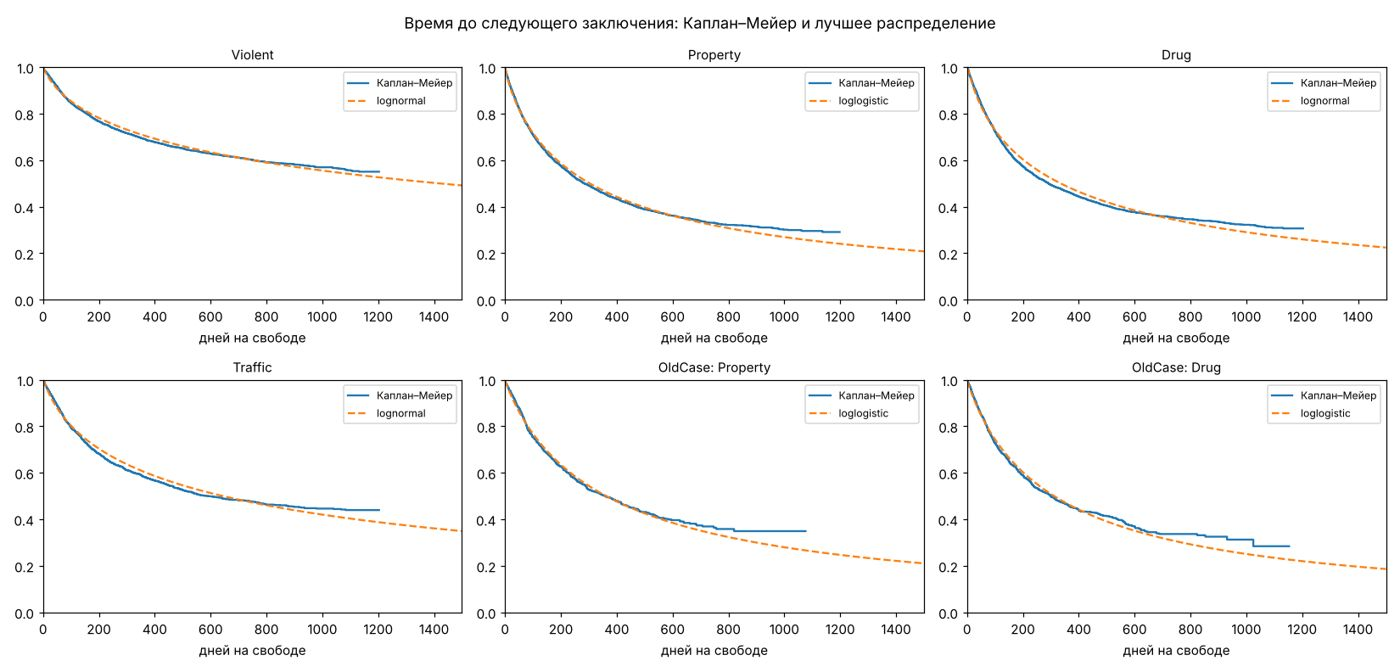

,n,events,km_median,S(365),S(730),weibull_rho,best,best_median
state,,,,,,,,
Violent,4538,1777,inf,0.690,0.605,0.618,lognormal,1421.2
Property,3570,2275,284.0,0.450,0.332,0.645,loglogistic,303.7
Drug,3328,2086,292.0,0.462,0.356,0.660,lognormal,335.7
Traffic,2234,1141,590.0,0.581,0.480,0.647,lognormal,644.0
OldCase: Property,1472,724,359.0,0.495,0.369,0.758,loglogistic,362.3
OldCase: Drug,1449,782,300.0,0.458,0.337,0.741,loglogistic,312.0
OldCase: Violent,817,388,411.0,0.524,0.414,0.721,loglogistic,427.2
Unknown,581,309,309.0,0.449,0.293,0.802,loglogistic,331.3
Fraud,526,264,579.0,0.586,0.480,0.666,loglogistic,642.4


In [12]:
state_dist, state_fits = ST.fit_state_distributions(E)
state_dist.to_csv(OUT23 / "state_time_distributions.csv")
top_states = list(state_dist.index[:6])
ST.plot_state_fits(state_fits, FIG23 / "state_time_fits.png", top_states,
                   "Время до следующего заключения: Каплан–Мейер и лучшее распределение")
show(FIG23 / "state_time_fits.png")
state_dist[["n", "events", "km_median", "S(365)", "S(730)", "weibull_rho", "best", "best_median"]]

**Как читать.** `km_median` — медиана Каплана–Мейера (дни; `inf` — больше половины не вернулись до конца
наблюдения), `S(365)` и `S(730)` — доля не вернувшихся за 1 и 2 года, `weibull_rho` — форма Вейбулла,
`best` — распределение с минимальным AIC и его медиана. Значения AIC всех распределений — в CSV.

### 2.4. Полумарковская модель: распределение времени на дуге

В полумарковской модели процесс задаётся двумя частями: вероятностями $p_{ij}$ (2.1) и распределением
времени $F_{ij}(t)$ при условии, что произошёл именно переход $i \to j$. Для дуг с не менее 30 переходами
подбираются Вейбулл, логнормальное и лог-логистическое распределения (только наблюдавшиеся переходы, без
цензуры), лучшее — по AIC. Условные распределения на дугах обычно с $\rho \approx 1$: падающий риск
в 2.3 получается в основном из-за смеси людей, которые вернутся, и тех, кто не вернётся.

In [13]:
arc_dist = ST.fit_arc_distributions(E)
arc_dist.to_csv(OUT23 / "arc_time_distributions.csv", index=False)
print("лучшее распределение на дугах:", arc_dist["best"].value_counts().to_dict())
print("доля дуг с формой Вейбулла rho < 1:", round(float((arc_dist["weibull_rho"] < 1).mean()), 3))
arc_dist.head(20)

лучшее распределение на дугах: {'weibull': 60, 'lognormal': 4}
доля дуг с формой Вейбулла rho < 1: 0.547


,from,to,n,median_days,weibull_lambda,weibull_rho,best_median,best
0,Property,OldCase: Property,927,146.0,215.8,1.048,152.1,weibull
1,Drug,OldCase: Drug,871,136.0,203.9,1.089,145.7,weibull
2,Property,Property,588,80.0,127.4,0.821,81.5,weibull
3,Violent,OldCase: Violent,537,140.0,207.1,0.974,142.1,weibull
4,Violent,Violent,459,134.0,198.3,0.914,132.8,weibull
5,OldCase: Drug,OldCase: Drug,458,106.5,153.3,1.072,108.9,weibull
6,Drug,Drug,454,102.0,156.8,0.915,105.1,weibull
7,OldCase: Property,OldCase: Property,446,92.0,144.7,1.023,101.1,weibull
8,Traffic,OldCase: Traffic,315,144.0,215.0,1.131,155.4,weibull
9,Traffic,Traffic,262,145.5,208.4,0.968,142.7,weibull


### 2.5. Конкурирующие риски: вероятность перейти в $j$ за $t$ дней

Из состояния $i$ человек может попасть в любое из состояний $j$ — это конкурирующие риски; цензура —
конец наблюдения. Оценка Аалена–Йохансена даёт кумулятивную функцию инцидентности
$\mathrm{CIF}_{ij}(t) = P(T \le t,\ K = j \mid i)$ — вероятность, что следующим будет заключение типа $j$ и
случится не позже $t$. В отличие от $p_{ij}$, она учитывает время и цензуру; сумма по $j$ — вероятность
любого нового заключения за $t$ (линия «любое» $= 1 - S(t)$ из 2.3). Таблица — для состояний с не менее
200 заключениями на горизонтах 90, 180, 365, 730 дней.

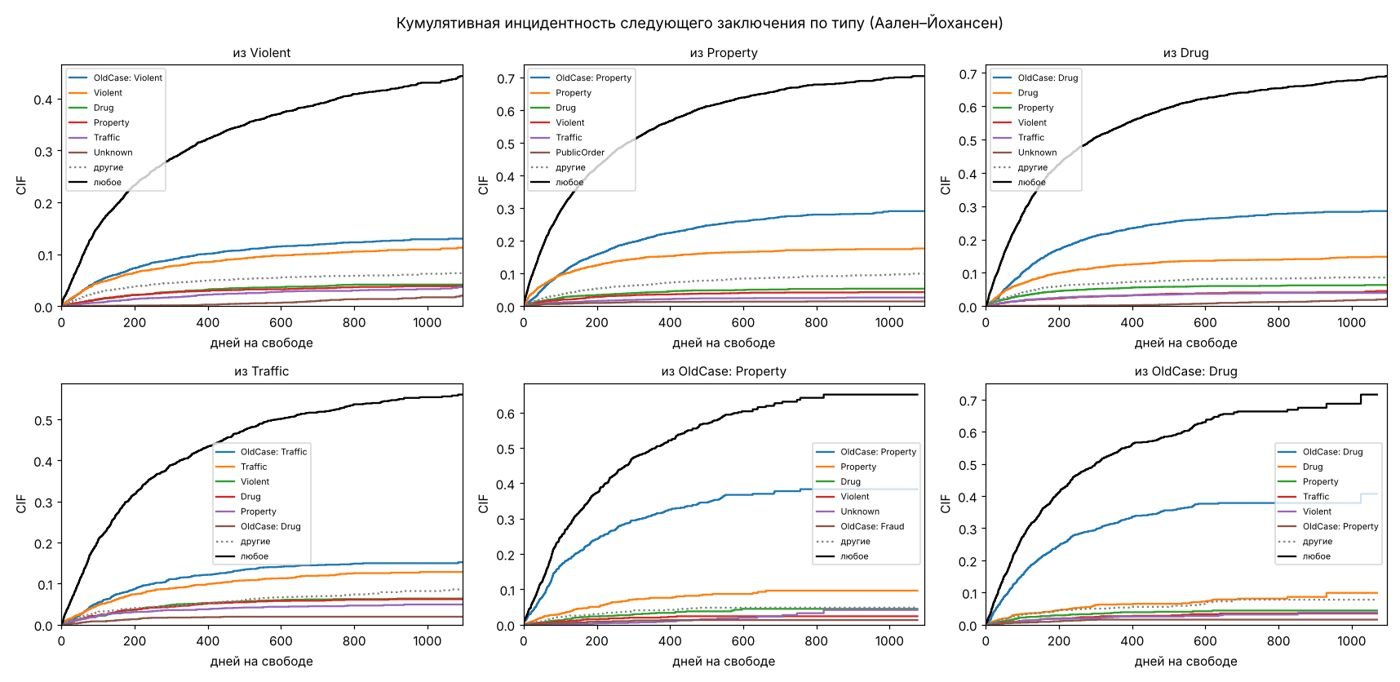

to,любое,OldCase: Property,OldCase: Drug,Property,Drug,Violent,OldCase: Violent,Traffic,OldCase: Traffic
from,,,,,,,,,
Violent,0.310,0.006,0.006,0.028,0.030,0.084,0.098,0.020,0.003
Property,0.550,0.218,0.012,0.151,0.043,0.036,0.008,0.021,0.003
Drug,0.538,0.012,0.226,0.054,0.123,0.031,0.006,0.031,0.006
Traffic,0.419,0.008,0.018,0.036,0.048,0.051,0.005,0.096,0.120
OldCase: Property,0.505,0.315,0.009,0.076,0.033,0.020,0.005,0.006,0.002
OldCase: Drug,0.542,0.016,0.320,0.038,0.064,0.025,0.004,0.026,0.007
OldCase: Violent,0.476,0.014,0.010,0.038,0.034,0.049,0.270,0.012,0.005
Unknown,0.551,0.022,0.008,0.058,0.072,0.066,0.008,0.042,0.002
Fraud,0.414,0.068,0.010,0.050,0.033,0.027,0.012,0.022,0.004


In [14]:
cif, cif_curves = ST.cumulative_incidence(E)
cif.to_csv(OUT23 / "cif_competing_risks.csv", index=False)
cif_states = list(cif_curves)[:6]
ST.plot_cif(cif_curves, FIG23 / "cif_top_states.png", cif_states,
            "Кумулятивная инцидентность следующего заключения по типу (Аален–Йохансен)")
show(FIG23 / "cif_top_states.png")
# вероятность за 1 год: строки — откуда, столбцы — куда (самые частые направления)
cif_1y = cif.pivot(index="from", columns="to", values="CIF_365d")
cols = ["любое"] + [c for c in cif[cif["to"] != "любое"].groupby("to")["events"].sum().sort_values(ascending=False).index[:8]]
cif_1y.reindex(index=[s for s in ST.state_order(E) if s in cif_1y.index], columns=cols).round(3)

## Этап 3. Признаки объекта и события, модели выживаемости между состояниями

Признаки (в моделях берутся строки с известным временем на свободе и баллом COMPAS):

| признак | что это | тип |
|---|---|---|
| `age10` | возраст на дату оценки COMPAS, на 10 лет (HR — на каждые 10 лет) | объект |
| `male` | мужчина | объект |
| `race_afam`, `race_other` | афроамериканец; другая раса (Hispanic, Asian, Native American, Other); база — Caucasian | объект |
| `score` | исходный балл COMPAS `decile_score` (1–10, риск рецидива) | объект |
| `felony` | самое тяжёлое обвинение заключения — фелония | событие |
| `n_charges` | число обвинений в заключении (до 10) | событие |
| `log_dur` | $\log(1 + \text{дней в заключении})$ | событие |
| `prior_eps` | сколько заключений было у человека раньше (до 5) | событие |
| `old_case` | в заключении есть обвинение по делу из прежнего заключения (нет у данных Даши) | событие |

Признаки объекта не меняются во времени. Балл COMPAS и возраст взяты на дату оценки COMPAS, которая для
части заключений позже их начала, — это свойство данных ProPublica (одна оценка на человека).
Люди делятся на train 80% / test 20% (seed 42), C-index (согласованность прогноза риска и времени;
0.5 — случайно, 1 — идеально) считается на test.

In [15]:
feats = ST.features_of(E)
R = ST.model_frame(E, feats)
train23, test23 = ST.split_people(R)
print("признаки:", feats)
print(f"строк для моделей: {len(R):,} (train {len(train23):,}, test {len(test23):,}); "
      f"событий в train: {int(train23['event'].sum()):,}")
R[feats].describe().T[["mean", "std", "min", "max"]].round(3)

признаки: ['age10', 'male', 'race_afam', 'race_other', 'score', 'felony', 'n_charges', 'log_dur', 'prior_eps', 'old_case']
строк для моделей: 21,067 (train 16,763, test 4,304); событий в train: 8,820


,mean,std,min,max
age10,3.368,1.141,1.8,9.600
male,0.817,0.387,0.0,1.000
race_afam,0.544,0.498,0.0,1.000
race_other,0.126,0.332,0.0,1.000
score,5.227,2.936,1.0,10.000
felony,0.642,0.480,0.0,1.000
n_charges,2.754,2.150,1.0,10.000
log_dur,1.985,1.668,0.0,7.085
prior_eps,1.023,1.355,0.0,5.000
old_case,0.255,0.436,0.0,1.000


### 3.1. CoxPH: время до следующего заключения любого типа

Модель пропорциональных рисков Кокса, **стратифицированная по текущему состоянию**: у каждого состояния свой
базовый риск $h_{0,i}(t)$, а признаки действуют одинаково, $h(t \mid i, x) = h_{0,i}(t)\, e^{\beta^\top x}$.
$\mathrm{HR} = e^\beta$ — во сколько раз признак меняет риск нового заключения (HR > 1 — возвращаются
быстрее). Ниже — сравнение C-index на test для моделей «только состояние», «только признаки»,
«состояние + признаки» (состояние — индикаторами, база — первое по алфавиту; состояния реже 30 заключений
в train остаются в базе) и HR состояний из последней модели.

In [16]:
cph, cox_hr, cox_cindex, cox_state_hr = ST.cox_any(train23, test23, feats)
cox_hr.to_csv(OUT23 / "cox_any_hr.csv")
cox_cindex.to_csv(OUT23 / "cox_cindex_test.csv", header=["c_index"])
cox_state_hr.to_csv(OUT23 / "cox_state_hr.csv")
print("C-index на test:")
print(cox_cindex.to_string())
cox_hr

C-index на test:
только состояние        0.5758
только признаки         0.6694
состояние + признаки    0.6740


,признак,HR,HR 95% низ,HR 95% верх,p
covariate,,,,,
age10,возраст (на 10 лет),0.986,0.966,1.006,0.1691
male,мужчина,1.231,1.163,1.303,0.0000
race_afam,афроамериканец,1.001,0.954,1.050,0.9800
race_other,др. раса (не белый),0.871,0.807,0.939,0.0003
score,балл COMPAS (decile),1.165,1.155,1.176,0.0000
felony,фелония,0.912,0.864,0.963,0.0009
n_charges,число обвинений,1.007,0.996,1.018,0.2084
log_dur,log длит. заключения,0.990,0.976,1.004,0.1738
prior_eps,заключений до этого,1.122,1.102,1.142,0.0000


In [17]:
# HR текущего состояния (модель «состояние + признаки»; база — первое по алфавиту состояние)
cox_state_hr.sort_values("HR")

,HR,p
OldCase: Sex,0.5268,0.0106
OldCase: Tampering,0.6119,0.0585
Violent,0.6508,0.0000
Tampering,0.7264,0.0031
OldCase: Traffic,0.7317,0.0009
OldCase: Fraud,0.7675,0.0448
OldCase: Violent,0.8136,0.0099
OldCase: Weapon,0.8190,0.2340
Unknown,0.8312,0.0114
OldCase: Property,0.8418,0.0132


### 3.2. Модели Кокса по дугам (причинно-специфичные риски)

Влияние признаков на **конкретный переход** $i \to j$: для людей в состоянии $i$ событие — следующее
заключение типа $j$, переходы в другие типы и конец наблюдения — цензура. Такая модель
причинно-специфичного риска $h_{ij}(t \mid x) = h_{0,ij}(t)\, e^{\beta_{ij}^\top x}$ — стандартный способ
оценивать признаки при конкурирующих рисках. Модели строятся на всех людях для дуг с не менее
`MIN_ARC_EVENTS` переходами (лёгкая L2-регуляризация, penalizer = 0.05, иначе на редких дугах коэффициенты
расходятся). Признак, постоянный внутри состояния, выпадает.

In [18]:
arc_cox = ST.cox_arcs(R, feats, min_events=MIN_ARC_EVENTS)
arc_cox.to_csv(OUT23 / "cox_arcs_hr.csv", index=False)
arc_effects = ST.arc_effects_summary(arc_cox, feats)
arc_effects.to_csv(OUT23 / "cox_arcs_feature_summary.csv")
print(f"дуг с моделью: {arc_cox['arc'].nunique()}")
arc_effects

дуг с моделью: 33


,дуг,HR>1 значимо,HR<1 значимо,медиана HR,мин HR,макс HR
возраст (на 10 лет),33,2,5,0.962,0.825,1.173
мужчина,33,7,0,1.128,0.735,2.097
афроамериканец,33,4,0,1.096,0.764,1.350
др. раса (не белый),33,0,3,0.880,0.488,1.278
балл COMPAS (decile),33,31,0,1.095,1.049,1.170
фелония,32,6,9,0.908,0.439,2.514
число обвинений,33,2,1,0.985,0.803,1.080
log длит. заключения,33,5,3,0.987,0.872,1.115
заключений до этого,33,12,0,1.068,0.955,1.238
старое дело в заключении,25,1,0,0.861,0.223,1.536


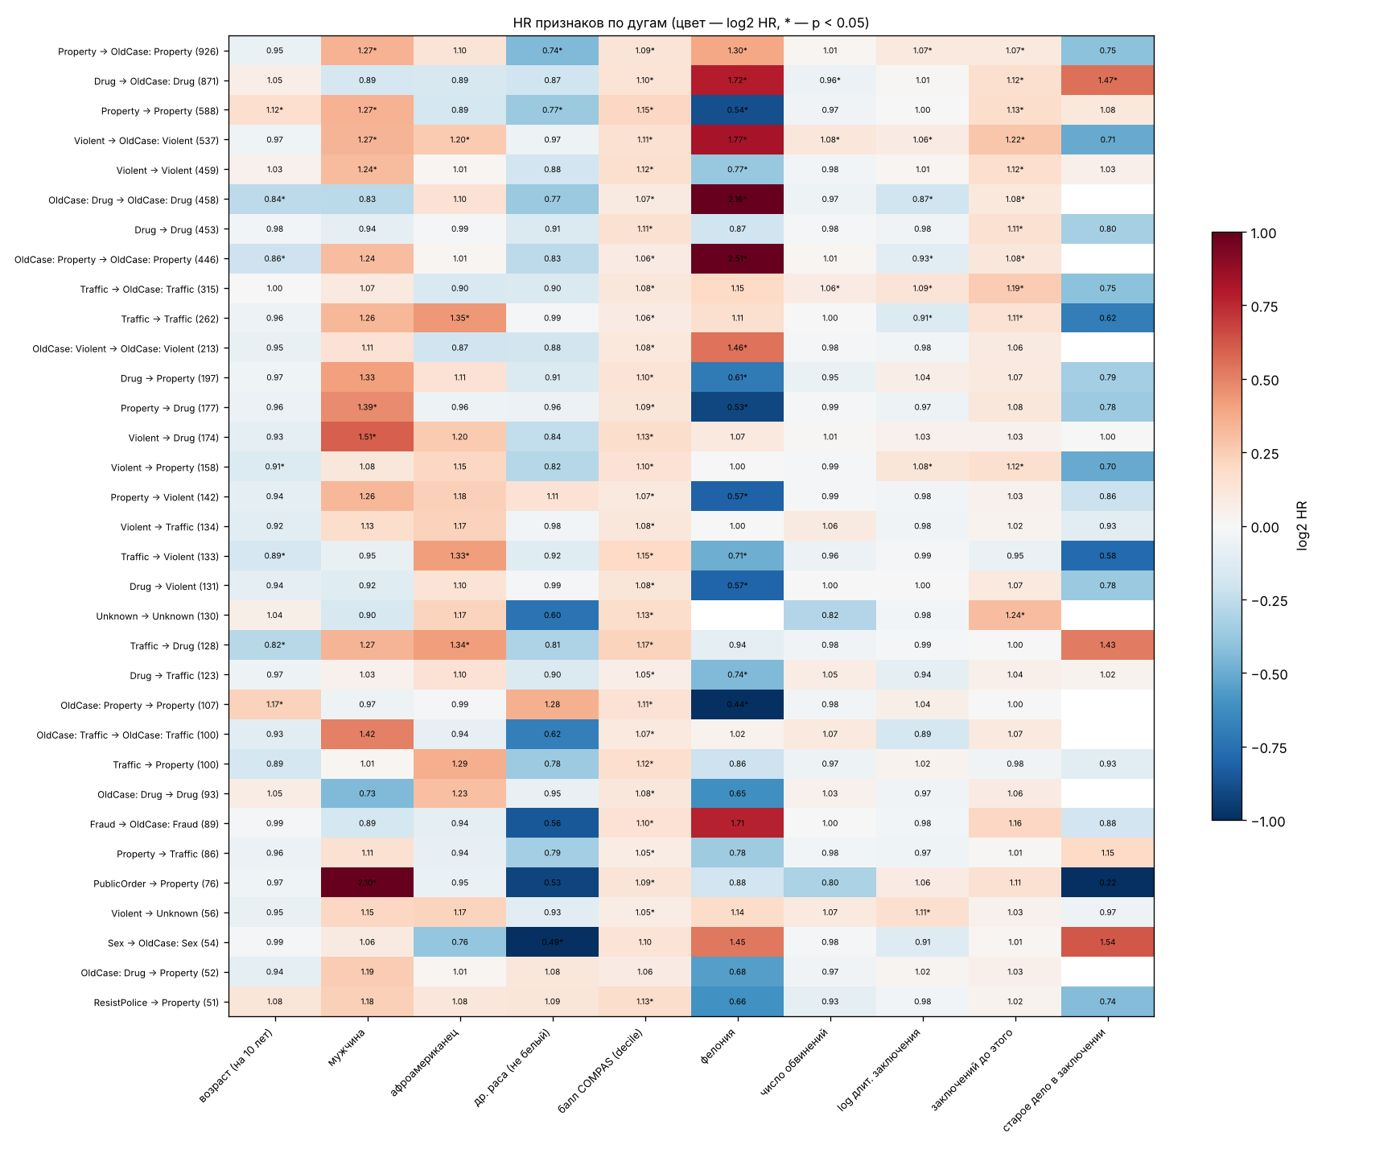

In [19]:
ST.plot_arc_heatmap(arc_cox, feats, FIG23 / "cox_arcs_heatmap.png",
                    "HR признаков по дугам (цвет — log2 HR, * — p < 0.05)")
show(FIG23 / "cox_arcs_heatmap.png")

**Как читать.** Таблица: на скольких дугах признак значимо (p < 0.05) ускоряет (HR > 1) или замедляет
(HR < 1) переход, медиана и размах HR. Тепловая карта — самые частые дуги (в скобках число переходов):
красное — признак ускоряет именно этот переход, синее — замедляет. Признак, который ускоряет одни переходы
и замедляет другие, меняет не только «скорость возвращения», но и **тип** следующего заключения.
Все HR и доверительные интервалы — в `cox_arcs_hr.csv`.

### 3.3. Дерево выживаемости

Дерево выживаемости (scikit-survival, разбиения по log-rank) для времени до следующего заключения: признаки
+ текущее состояние. Глубина 3, в листе не меньше 300 заключений, чтобы дерево читалось. Листья
отсортированы от самого быстрого возвращения: `km_median` — медиана Каплана–Мейера в листе, `S365` — доля
не вернувшихся за год. Ниже — кривые Каплана–Мейера листьев.

C-index дерева на test: 0.6530


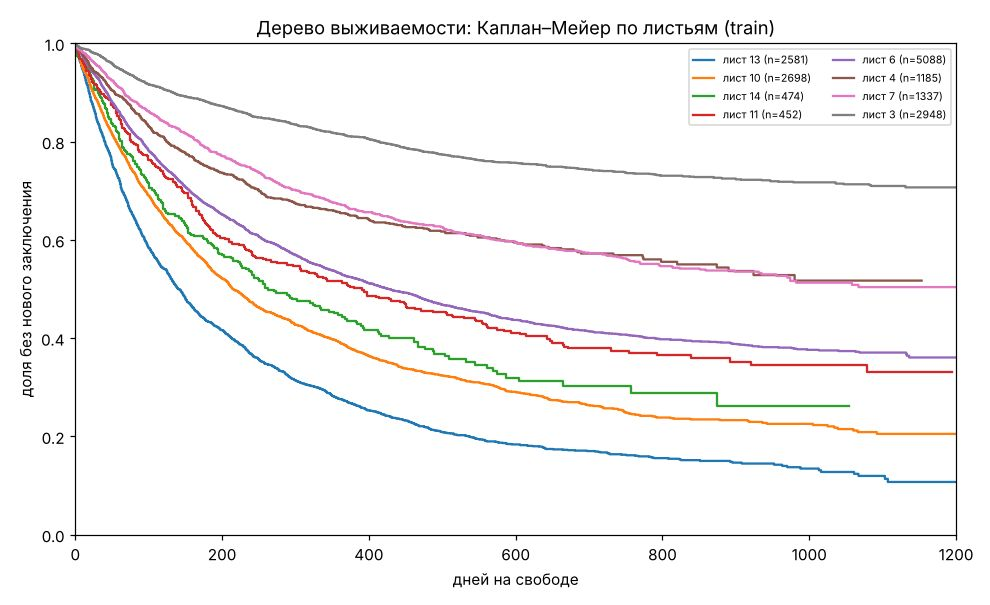

,leaf,path,n,events,km_median,S365
0,13,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,2581,1976,141.0,0.273
1,10,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,2698,1792,215.0,0.388
2,14,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,474,264,263.0,0.443
3,11,балл COMPAS (decile) > 6.50 и балл COMPAS (dec...,452,270,391.0,0.513
4,6,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,5088,2726,427.0,0.528
5,4,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,1185,431,inf,0.655
6,7,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,1337,575,inf,0.671
7,3,балл COMPAS (decile) ≤ 6.50 и балл COMPAS (dec...,2948,786,inf,0.815


In [20]:
tree23, leaves23, tree_c = ST.survival_tree(train23, test23, feats)
leaves23.to_csv(OUT23 / "survival_tree_leaves.csv", index=False)
print(f"C-index дерева на test: {tree_c:.4f}")
ST.plot_tree_leaves(train23, tree23, feats, leaves23, FIG23 / "survival_tree_leaves.png",
                    "Дерево выживаемости: Каплан–Мейер по листьям (train)")
show(FIG23 / "survival_tree_leaves.png")
leaves23

### 3.4. Случайный лес выживаемости и важность признаков

Random Survival Forest (100 деревьев, лист от 50 заключений) — нелинейная модель для сравнения с Коксом.
Важность признака — насколько падает C-index на test, если перемешать этот признак (текущее состояние
перемешивается целиком). Флаг `RUN_RSF = False` пропускает этот шаг.

In [21]:
if RUN_RSF:
    rsf_c, rsf_imp, rsf_sec = ST.random_forest(train23, test23, feats)
    rsf_imp.to_csv(OUT23 / "rsf_permutation_importance.csv", header=["drop_in_c_index"])
    print(f"RSF: C-index на test {rsf_c:.4f} ({rsf_sec} с)")
    display(rsf_imp.to_frame("падение C-index"))
else:
    rsf_c, rsf_imp = float("nan"), pd.Series(dtype=float)

cindex_all = pd.concat([cox_cindex.rename(lambda s: "Кокс: " + s),
                        pd.Series({"дерево выживаемости": round(tree_c, 4), "случайный лес": round(rsf_c, 4)})])
cindex_all.to_csv(OUT23 / "cindex_all_models.csv", header=["c_index"])
ST.save_excel(OUT23 / "stage23_tables.xlsx", {
    "сводка": ST.episodes_summary(E).to_frame("значение"), "переходы_число": cnt, "переходы_p": P.round(4),
    "переходы_сводка": trans_summary, "время_дуги": arcs23, "время_состояния": state_dist,
    "распр_дуги": arc_dist, "CIF": cif, "cox_hr": cox_hr, "cox_состояния": cox_state_hr,
    "cox_дуги": arc_cox, "cox_дуги_сводка": arc_effects, "дерево_листья": leaves23,
    "rsf_важность": rsf_imp.to_frame("падение C-index"), "c_index": cindex_all.to_frame("c_index")})
cindex_all.to_frame("C-index (test)")

RSF: C-index на test 0.6775 (6 с)


,падение C-index
балл COMPAS (decile),0.0826
заключений до этого,0.0162
текущее состояние,0.0161
log длит. заключения,0.0045
фелония,0.0029
мужчина,0.0025
старое дело в заключении,0.0022
возраст (на 10 лет),0.0009
др. раса (не белый),0.0007
число обвинений,0.0006


таблицы: /tmp/claude-0/w/jl/stage1/x2_exp1_one_event/out/stage23/stage23_tables.xlsx


,C-index (test)
Кокс: только состояние,0.5758
Кокс: только признаки,0.6694
Кокс: состояние + признаки,0.6740
дерево выживаемости,0.6530
случайный лес,0.6775


## Итоги этапов 2–3 (эксп. 1)

**Этап 2. Параметры переходов.** 21 716 заключений 10 580 человек, 28 состояний, 11 136 наблюдавшихся переходов;
последнее заключение каждого человека цензурировано (635 человек ещё в заключении на конец наблюдения).
- Вероятности: из новых категорий петля X → X 0.22–0.26, а самый частый переход — в старое дело того же типа
  (Drug → OldCase: Drug 0.42, Property → OldCase: Property 0.41); из `OldCase: X` петля 0.44–0.62.
- Время на свободе: медиана 124 дня; на частых дугах 80–150 дней (быстрее всего Property → Property, 80).
- Из состояния (с цензурой): за год возвращаются 45–55% после Property, Drug, OldCase: Drug, но только 31% после
  Violent (Каплан–Мейер, S(365) = 0.69). Форма Вейбулла ρ = 0.56–0.80 < 1: риск нового заключения максимален
  сразу после выхода и падает; по AIC лучше логнормальное и лог-логистическое распределения.
- На отдельных дугах (полумарковская модель) время при условии перехода — почти экспоненциальное
  (Вейбулл, ρ ≈ 0.8–1.1): падающий риск в целом создаётся смесью «вернутся» и «не вернутся».

**Этап 3. Признаки.** Кокс, стратифицированный по состоянию (HR, p < 0.05):
балл COMPAS 1.165 на 1 дециль, предыдущее заключение 1.12 на каждое, мужчина 1.23, другая раса 0.87 (к белым),
фелония 0.91. Возраст, афроамериканец (при учёте балла), число обвинений, длительность и старое дело — незначимы.
- C-index на test: только состояние 0.576, только признаки 0.669, вместе 0.674, дерево 0.653, лес 0.678.
  Перестановочная важность в лесу: балл COMPAS 0.083, число прошлых заключений 0.016, текущее состояние 0.016.
- По 33 дугам: балл COMPAS ускоряет 31 переход; фелония разводит направления — ускоряет повтор по старому делу
  (OldCase: Property → OldCase: Property HR 2.5, OldCase: Drug → OldCase: Drug 2.2, Violent → OldCase: Violent 1.8)
  и замедляет смену типа (Property → Drug 0.53, OldCase: Property → Property 0.44).
- Дерево: первое разбиение — балл COMPAS (6.5 и 8.5), дальше состояние Violent и число прошлых заключений.
  Самый быстрый лист — балл 9–10 и короткое заключение: медиана 141 день, за год возвращаются 73%;
  самый медленный — балл 1–2 и первое заключение: за год 19%.

**Сравнение кейсов** (C-index на test; Кокс «состояние + признаки» / только состояние / случайный лес):
эксп. 1 — 0.674 / 0.576 / 0.678; эксп. 3 — 0.675 / 0.577 / 0.678; данные Даши — 0.679 / 0.575 / 0.678;
15 категорий all_new — 0.674 / 0.572 / 0.677; oldcase — 0.675 / 0.578 / 0.678. Во всех кейсах картина одна:
скорость возвращения определяют в основном признаки человека, а тип текущего заключения добавляет немного;
зато тип влияет на то, **куда** человек перейдёт (матрица переходов, CIF и модели по дугам).

**Ограничения.** Балл COMPAS и возраст взяты на дату оценки COMPAS (одна на человека), для части заключений она
позже их начала. HR в моделях по дугам — без поправки на множественные сравнения (много дуг × 10 признаков),
поэтому одиночные значимые HR на редких дугах — ориентиры, а не выводы. Пропорциональность рисков не
проверялась формально; дерево и лес её не требуют и дают близкий C-index.
